# FCC-ee HEB RF — IDDEFIX **Option 1: full HOM-only impedance + wake and budget-file exports**

**Standalone executable notebook.** Reuses the v14/v15 **fixed-\(Q\), local magnitude-fitting** procedure to identify four resonances from the **100 m CST longitudinal bunch wake** (Gaussian bunch, \(\sigma_z=10\,\mathrm{mm}\)). The four-mode fit is used *only to determine parameters and validate the finite wake*. The final passive RF model is **three infinite-wakelength HOMs**; the actively operated **800 MHz fundamental (FM) is omitted**.

\[
\boxed{Z_{\mathrm{RF,HOM}}(f)=\sum_{j\in\{\mathrm{HM1,HM2,HM3}\}}
\frac{R_{s,j}}{1+iQ_j\left(f/f_j-f_j/f\right)}}\qquad (f>0).
\]

**No frequency-domain or wake-domain subtraction, no finite-wake replacement, and no Option 2/3.** We deliberately do **not** force the fit to reproduce every secondary CST peak. We preserve fit residuals so omitted modes are documented. The original CST \(\Re Z\) can be negative because the 100 m wake is truncated; the full passive HOM-only model has nonnegative \(\Re Z\) for positive \(R_s\).

**Inputs:** `data/rf_cavities/Wp_single800mhz_wake100.txt` and optional CST magnitude export. **Outputs:** fitted-parameter table, three-panel plots for the full band and every mode, and *adaptive-frequency* HOM-only impedance files up to 50 GHz. This revision also generates per-cavity longitudinal impedance, point-charge wake, and Gaussian-bunch wake-potential tables **directly in `data/rf_cavities/`**, without overwriting the original CST data. **Outputs do not overwrite the official RF impedance budget.**

The notebook uses **native `iddefix.Impedances.Resonator_longitudinal_imp`** when IDDEFIX is installed. For portability, an embedded analytically equivalent Q>0.5 formula is used if `iddefix` is unavailable, and the active backend is reported. To install in your environment, use `python -m pip install -U iddefix`.

**Important:** This produces a candidate **longitudinal HOM-only** RF model, not a complete cavity model, and does not modify `heb_gold_tl.py` or the official V26.2 budget input. Transverse RF models are unchanged.


In [1]:
from __future__ import annotations
from pathlib import Path
from dataclasses import dataclass
from scipy.constants import c
from scipy.fft import dct, dst, next_fast_len
from scipy.signal import CZT
from scipy.optimize import minimize_scalar
from scipy.integrate import trapezoid
from IPython.display import display, Markdown
import numpy as np
import matplotlib.pyplot as plt
import json, csv, re

try:
    import iddefix
    IDDEFIX_BACKEND = "native iddefix"
except ImportError:
    iddefix = None
    IDDEFIX_BACKEND = "embedded exact IDDEFIX resonator formulas (iddefix not installed)"

# Edit only if needed. The notebook also searches a few parent folders.
ROOT = Path.cwd().resolve()
DATA = ROOT / "data" / "rf_cavities"
RESULTS = ROOT / "results" / "RF_IDDEFIX_option1_HOM_only"

# Reuse the v14/v15 fit settings. Q values are externally fixed assumptions,
# not measurements of the 100 m CST wake. Rs and fr are fitted locally to |Z|.
FIT_METHOD = "magnitude"  # v14/v15 primary fit; intentionally no complex refit
N_RF_CAVITIES = 112
SIGMA_BUDGET_M = 0.004
FMAX_EXPORT_HZ = 50e9
PLOT_DF_HZ = 0.2e6  # oversamples finite-record Fourier integral, not new information
PLOT_FMAX_HZ = 3.55e9

MODES = (
    {"name": "FM",         "f_ref": 801.584e6, "Q": 1.10e7, "half": 20e6},
    {"name": "HM1_1p494", "f_ref": 1.494e9,   "Q": 3800.,  "half": 25e6},
    {"name": "HM2_2p368", "f_ref": 2.368e9,   "Q": 4900.,  "half": 30e6},
    {"name": "HM3_3p38",  "f_ref": 3.380e9,   "Q": 8200.,  "half": 35e6},
)

required = ("Wp_single800mhz_wake100.txt", "Z_single800mhz_wake100.txt")
if not all((DATA / name).is_file() for name in required):
    roots = [ROOT, *list(ROOT.parents)[:3], ROOT / "fcc_ee_booster_pywit_model"]
    candidates = [p / "data" / "rf_cavities" for p in roots] + [p / "data" for p in roots] + roots
    DATA = next((p for p in candidates if all((p / name).is_file() for name in required)), DATA)
if not all((DATA / name).is_file() for name in required):
    raise FileNotFoundError(
        f"CST files not found in {DATA}. Set DATA to the folder with "
        "Wp_single800mhz_wake100.txt and Z_single800mhz_wake100.txt."
    )
RESULTS.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)
print("DATA:", DATA)
print("RESULTS:", RESULTS)
print("Resonator backend:", IDDEFIX_BACKEND)

ROOT: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model
DATA: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities
RESULTS: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only
Resonator backend: native iddefix


## 1 · Read the original CST **bunch wake** and validate its conventions

CST provides \(W_p(s)\) in V/pC as a function of longitudinal position in mm; the v14 longitudinal sign convention is applied **once** as \(W_{\mathrm{IDDEFIX}}=-10^{12}W_{\mathrm{CST}}\) in V/C. We retain the negative-\(s\) part of the finite Gaussian bunch potential when transforming. No arbitrary wake shift or post-fit sign change is applied.

In [2]:
@dataclass
class CST:
    s: np.ndarray
    wake: np.ndarray
    ds: float
    sigma: float
    length: float

def read_cst(data_dir: Path) -> CST:
    fn = data_dir / "Wp_single800mhz_wake100.txt"
    arr = np.loadtxt(fn, comments="#")
    header = fn.open(encoding="utf8").readline()
    props = dict((k, float(v)) for k, v in re.findall(
        r"([A-Za-z_]+)\s*=\s*([-+0-9.eE]+)", header
    ))
    if "sigma_z" not in props or "wakelength_long" not in props:
        raise ValueError("Could not parse sigma_z and wakelength_long from CST header")
    s = arr[:, 0] * 1e-3
    wake = -arr[:, 1] * 1e12  # exactly the single CST->IDDEFIX sign conversion in v15
    ds = float(np.median(np.diff(s)))
    if not np.allclose(np.diff(s), ds, rtol=3e-6, atol=1e-10):
        raise ValueError("Non-uniform CST wake grid")
    sigma, length = props["sigma_z"] * 1e-3, props["wakelength_long"] * 1e-3
    if not (abs(sigma - 0.010) < 1e-9 and abs(length - 100.0) < 1e-5):
        raise ValueError("This script requires the v15 100 m / 10 mm CST dataset")
    return CST(s, wake, ds, sigma, length)

cst = read_cst(DATA)
print(f"CST: {len(cst.s):,} samples, s = {cst.s[0]:.6f} ... {cst.s[-1]:.6f} m, ds = {cst.ds*1e3:.6f} mm")
print(f"Wake length {cst.length:g} m; sigma_z = {cst.sigma*1e3:g} mm")
assert cst.s[0] < 0 and cst.s[-1] > 99.9

CST: 727,801 samples, s = -0.085489 ... 99.999954 m, ds = 0.137518 mm
Wake length 100 m; sigma_z = 10 mm


## 2 · DCT/DST impedance and exact-frequency comparison

The signed longitudinal impedance is obtained from the entire **two-sided** bunch wake using paired cosine/sine transforms, then divided by \(\tilde\lambda(f)=\exp[-(2\pi f\sigma_z/c)^2/2]\). A dense chirp-Z transform (CZT) evaluates **the same integral** at the local fit frequencies; it does *not* improve the physical resolution \(\Delta f\sim c/L\approx3\,\mathrm{MHz}\).

In [3]:
def dct_dst_z(cst: CST, fmax: float = 3.55e9):
    """v15 two-sided paired DCT-I/DST-I Gaussian deconvolution, signed."""
    M = next_fast_len(int(np.ceil(cst.s[-1] / cst.ds)) + 1)
    x = np.arange(M + 1) * cst.ds
    pos = np.interp(x, cst.s, cst.wake, left=0., right=0.)
    neg = np.interp(-x, cst.s, cst.wake, left=0., right=0.)
    dt = cst.ds / c
    zr = dt / 2 * (dct(pos, type=1) + dct(neg, type=1))
    zi = np.zeros_like(zr)
    zi[1:-1] = dt / 2 * (dst(neg[1:-1], type=1) - dst(pos[1:-1], type=1))
    k = min(M, int(np.floor(fmax * 2 * M * cst.ds / c)))
    f = np.arange(k + 1) * c / (2 * M * cst.ds)
    gauss = np.exp(-0.5 * (2 * np.pi * f * cst.sigma / c)**2)
    return f, (zr[:k+1] + 1j * zi[:k+1]) / gauss

def czt_z(cst: CST, f0: float, df: float, n: int):
    """Exact-frequency integral on the original two-sided CST sample grid.

    This oversamples the *existing* Fourier integral: it does not recover
    independent frequency resolution finer than approximately c/L.
    """
    f = f0 + np.arange(n, dtype=float) * df
    calc = CZT(n=len(cst.wake), m=n,
               w=np.exp(-2j * np.pi * df * cst.ds / c),
               a=np.exp(2j * np.pi * f0 * cst.ds / c))
    z = (cst.ds / c) * calc(cst.wake) * np.exp(-2j * np.pi * f * cst.s[0] / c)
    gauss = np.exp(-0.5 * (2 * np.pi * f * cst.sigma / c)**2)
    return f, z / gauss

f_dct, z_dct = dct_dst_z(cst, fmax=PLOT_FMAX_HZ)
_, z_czt_dct = czt_z(cst, 0., float(f_dct[1]-f_dct[0]), len(f_dct))
dct_error = np.linalg.norm(z_dct - z_czt_dct) / np.linalg.norm(z_dct)
print(f"DCT/DST vs CZT check: relative complex L2 error = {dct_error:.3e}")
assert dct_error < 1e-3

# CST export is |Z| only; check it at its *exact* native frequencies.
native = np.loadtxt(DATA / "Z_single800mhz_wake100.txt", comments="#")
fnative = native[:,0]*1e9
f_export, z_native = czt_z(cst, float(fnative[0]), float(np.median(np.diff(fnative))), len(fnative))
assert np.allclose(f_export, fnative, rtol=0, atol=2e3)
mask = (fnative >= 0.25e9) & (fnative <= PLOT_FMAX_HZ) & (native[:,1] > 0)
rel_native = np.abs(np.abs(z_native[mask])-native[mask,1]) / native[mask,1]
print(f"Original CST |Z| export crosscheck, median rel. diff. = {np.median(rel_native)*100:.3f}%")

DCT/DST vs CZT check: relative complex L2 error = 2.618e-05
Original CST |Z| export crosscheck, median rel. diff. = 0.046%


## 3 · Fit the finite-length IDDEFIX resonators (same v14/v15 procedure)

For each of the four modes, fixed external \(Q_L\), scan within \(\pm c/L\) of its reference frequency, subtract a local **magnitude** baseline estimated from the outer part of its window, optimize frequency, and solve \(R_s\ge0\) by one-parameter linear least squares. **The FM is fitted for comparison only; it will not appear in the exported Option 1 model.** In the code's convention, the reported \(R/Q=2R_s/Q_L\).

In [4]:
def _embedded_finite(f, Rs, Q, fr, L):
    """IDDEFIX Q>0.5 finite-wakelength longitudinal impedance (v0.3.x)."""
    f = np.asarray(f, dtype=float)
    omega = 2*np.pi*f
    om0 = 2*np.pi*fr
    B = om0/(2*Q)
    C = om0*np.sqrt(1-1/(4*Q*Q))
    ss = B+1j*omega
    T = L/c
    term = np.exp(-ss*T)
    num = 1j*omega + term * (-1j*omega*np.cos(C*T) + (C*C+B*ss)*np.sin(C*T)/C)
    return Rs * om0/Q * num/(C*C+ss*ss)

def _embedded_full(f, Rs, Q, fr):
    """IDDEFIX infinite-wakelength passive longitudinal resonator impedance."""
    f = np.asarray(f, dtype=float)
    z = np.zeros_like(f, dtype=complex)
    positive = f > 0
    ff = f[positive]
    z[positive] = Rs*ff*fr/(ff*fr+1j*Q*(ff*ff-fr*fr))
    return z

def iddefix_finite(f, Rs, Q, fr, L):
    if iddefix is not None:
        return iddefix.Impedances.Resonator_longitudinal_imp(
            np.asarray(f, dtype=float), Rs, Q, fr, wake_length=L)
    return _embedded_finite(f, Rs, Q, fr, L)

def iddefix_full(f, Rs, Q, fr):
    if iddefix is not None:
        return iddefix.Impedances.Resonator_longitudinal_imp(
            np.asarray(f, dtype=float), Rs, Q, fr, wake_length=None)
    return _embedded_full(f, Rs, Q, fr)

# Internal mathematical consistency of both backends if IDDEFIX is installed.
probe_f = np.array([0.1, 0.7, 1.492, 1.495, 2.368, 3.38, 5.0])*1e9
if iddefix is not None:
    for fn, embedded, L in [(iddefix_full, _embedded_full, None),
                            (iddefix_finite, _embedded_finite, 100.)]:
        a = fn(probe_f, 50_000., 3800., 1.494e9, L) if L else fn(probe_f, 50_000., 3800., 1.494e9)
        b = embedded(probe_f, 50_000., 3800., 1.494e9, L) if L else embedded(probe_f, 50_000., 3800., 1.494e9)
        err = np.linalg.norm(a-b)/np.linalg.norm(b)
        print(f"Native IDDEFIX formula check: {err:.3e}")
        assert err < 1e-6

Native IDDEFIX formula check: 0.000e+00
Native IDDEFIX formula check: 5.801e-17


In [5]:
def fit_one(cst: CST, mode: dict, method: str) -> dict:
    """Reproduce v15's fixed-Q local fit (including its baseline definition)."""
    f0, half, Q = mode["f_ref"], mode["half"], mode["Q"]
    df = 0.20e6
    ff, zz = czt_z(cst, f0-half, df, int(np.floor(2*half/df)) + 1)
    # Same strict local-window mask as v15; avoids using endpoint samples.
    selected = abs(ff-f0) < half
    ff, zz = ff[selected], zz[selected]
    outer = abs(ff-f0) > (1-.18)*half
    if method == "magnitude":
        baseline = float(np.median(abs(zz[outer])))
        y = np.maximum(abs(zz)-baseline, 0.)
    else:
        baseline = np.median(zz[outer].real) + 1j*np.median(zz[outer].imag)
        y = zz-baseline

    def evaluate(fr, details=False):
        unit = iddefix_finite(ff, 1., Q, fr, cst.length)
        if method == "magnitude":
            unit = abs(unit)
        Rs = max(0., float(np.vdot(unit,y).real/np.vdot(unit,unit).real))
        residual = np.linalg.norm(y-Rs*unit)/max(np.linalg.norm(y), 1e-20)
        return (residual, Rs) if details else residual

    limit = c/cst.length
    trial = np.linspace(f0-limit, f0+limit, 161)
    score = np.array([evaluate(x) for x in trial])
    ind = np.argmin(score)
    seed = trial[ind]
    step = trial[1]-trial[0]
    lo, hi = max(f0-limit,seed-2*step), min(f0+limit,seed+2*step)
    fr = float(minimize_scalar(evaluate, bounds=(lo,hi),method="bounded",
                               options={"xatol":5.}).x) if hi>lo else float(seed)
    relative, Rs = evaluate(fr, details=True)
    return {"name":mode["name"],"fit_type":method,"Q_fixed":Q,
            "f_fit_hz":fr,"Rs_Ohm":Rs,"R_over_Q_Ohm":2*Rs/Q,
            "relative_local_residual":float(relative),
            "at_frequency_boundary":bool(abs(fr-f0)>=.95*limit)}

fits = [fit_one(cst, mode, FIT_METHOD) for mode in MODES]
print("\nProvisional fixed-Q fits; one RF cavity:")
print(f"{'Mode':14s} {'f_fit [MHz]':>15s} {'Q_L':>11s} {'R/Q [Ω]':>12s} {'Local residual':>16s} {'Bound?':>8s}")
for row in fits:
    print(f"{row['name']:14s} {row['f_fit_hz']/1e6:15.5f} {row['Q_fixed']:11.0f} {row['R_over_Q_Ohm']:12.3f} {100*row['relative_local_residual']:15.1f}% {str(row['at_frequency_boundary']):>8s}")
with (RESULTS / 'IDDEFIX_v15_fixedQ_magnitude_fits.csv').open('w', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(fits[0].keys()))
    writer.writeheader(); writer.writerows(fits)

hom_fits = [r for r in fits if r['name'] != 'FM']
assert len(hom_fits) == 3 and all(r['Rs_Ohm'] > 0 for r in hom_fits)
print("\nOption 1: using ONLY", ", ".join(x['name'] for x in hom_fits), "(FM excluded)")
if any(r['at_frequency_boundary'] or r['relative_local_residual'] > .3 for r in hom_fits):
    print("CAUTION: some fitted HOM parameters have large local residuals / a frequency-bound hit.")


Provisional fixed-Q fits; one RF cavity:
Mode               f_fit [MHz]         Q_L      R/Q [Ω]   Local residual   Bound?
FM                   801.60194    11000000      576.685            11.9%    False
HM1_1p494           1496.99789        3800       46.286            56.4%     True
HM2_2p368           2367.36395        4900       27.317             9.9%    False
HM3_3p38            3381.68102        8200        8.332            33.2%    False

Option 1: using ONLY HM1_1p494, HM2_2p368, HM3_3p38 (FM excluded)
CAUTION: some fitted HOM parameters have large local residuals / a frequency-bound hit.


## 4 · Construct **Option 1 only** and inspect its passivity

- Original CST: raw signed DCT/DST/CZT finite-wake spectrum.
- IDDEFIX fit: sum of **all four finite-length** resonators, for checking the fit.
- **Option 1**: sum of **three full-length HOMs only**, with \(R_s>0\), no FM and no broadband CST remainder.

We do not subtract, splice, filter or clip the CST spectrum. The FM may leave a small off-resonance **HOM tail** near 800 MHz, but there is no 800 MHz resonator in Option 1.

In [6]:
n_plot = int(np.floor(PLOT_FMAX_HZ / PLOT_DF_HZ)) + 1
f_plot, z_cst = czt_z(cst, 0., PLOT_DF_HZ, n_plot)
z_iddefix_finite = sum((iddefix_finite(f_plot, r['Rs_Ohm'], r['Q_fixed'],
                                        r['f_fit_hz'], cst.length) for r in fits),
                        np.zeros_like(f_plot, dtype=complex))
z_option1 = sum((iddefix_full(f_plot, r['Rs_Ohm'], r['Q_fixed'], r['f_fit_hz'])
                 for r in hom_fits), np.zeros_like(f_plot, dtype=complex))
assert np.max(np.abs(z_option1.imag)) > 0
assert np.min(z_option1.real) > -1e-8
print("Option 1 min Re Z on dense grid:", float(z_option1.real.min()), "Ohm / cavity")
print("Check: no FM resonance in Option 1, and Re Z >= 0 across test grid.")

Option 1 min Re Z on dense grid: 0.0 Ohm / cavity
Check: no FM resonance in Option 1, and Re Z >= 0 across test grid.


## 5 · Graphs: \(\Re Z\), \(\Im Z\) and \(|Z|\) with **three curves**

The CST curve is **solid**, the finite four-resonator IDDEFIX fit is **dashed**, and Option 1 is **dash-dot**. There are **no Options 2 or 3**. Axes use `symlog` for signed real/imaginary impedance and `log` for magnitude. Each graph is **displayed inline** and saved as a PNG; you do not need to load a PNG from disk just to see it.

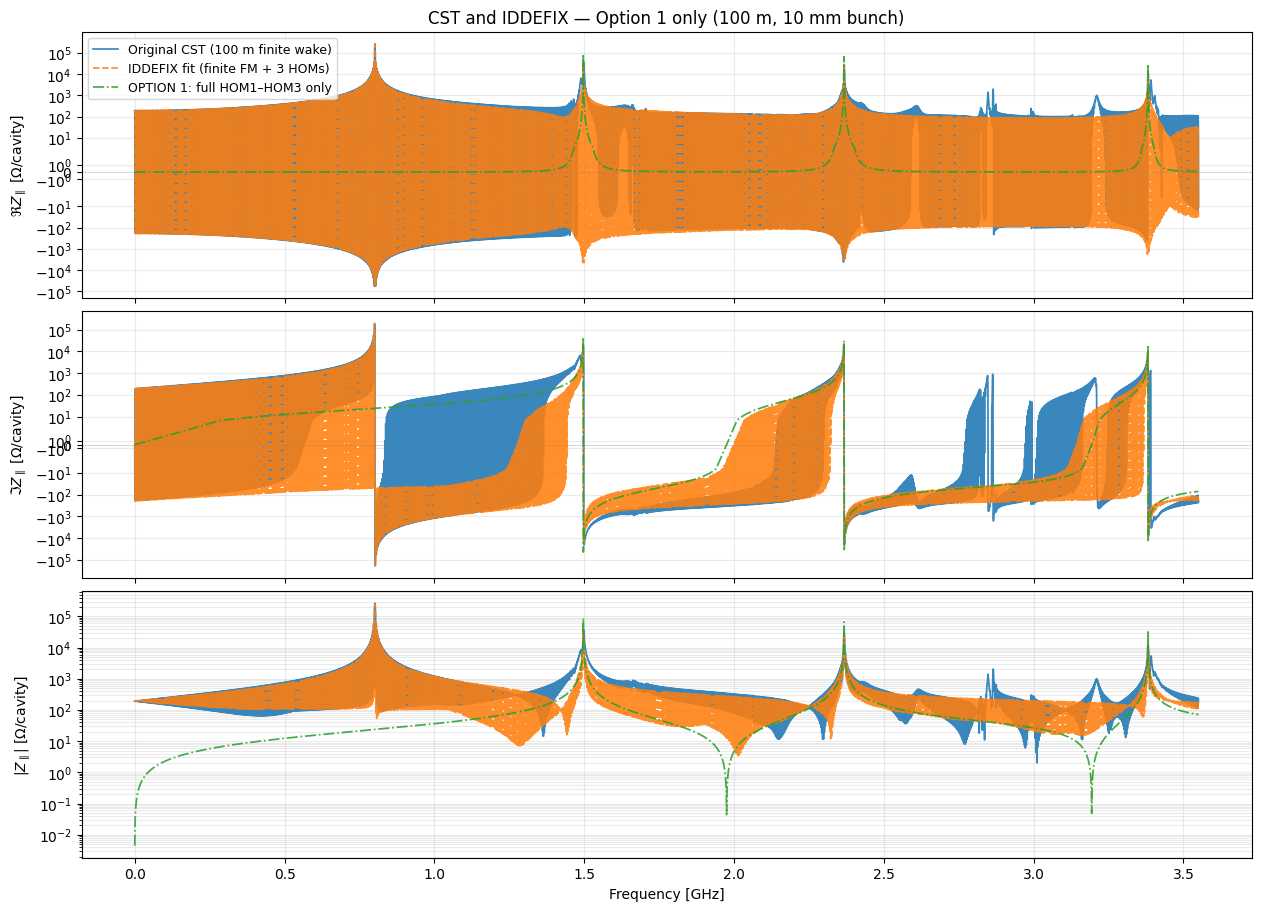

In [7]:
LEGEND = (
    "Original CST (100 m finite wake)",
    "IDDEFIX fit (finite FM + 3 HOMs)",
    "OPTION 1: full HOM1–HOM3 only",
)
STYLES = ("-", "--", "-.")  # solid is used ONLY for the original CST data

def plot_impedance(f_hz, curves, title, save_name, *, full=False):
    fig, axs = plt.subplots(3, 1, figsize=(12.5, 9.0), sharex=True,
                            layout="constrained")
    funcs = (np.real, np.imag, np.abs)
    labels = (r"$\Re Z_{\parallel}$ [$\Omega$/cavity]",
              r"$\Im Z_{\parallel}$ [$\Omega$/cavity]",
              r"$|Z_{\parallel}|$ [$\Omega$/cavity]")
    for k, (ax, func, ylabel) in enumerate(zip(axs, funcs, labels)):
        vals = []
        for z, name, linestyle in zip(curves, LEGEND, STYLES):
            y = func(z)
            if k == 2: y = np.where(y > 0, y, np.nan)
            ax.plot(f_hz*1e-9, y, linestyle=linestyle, linewidth=1.25,
                    label=name, alpha=.88)
            vals.append(np.abs(y[np.isfinite(y)]))
        if k == 2:
            ax.set_yscale("log")
        else:
            vv = np.concatenate(vals)
            linthresh = max(1., float(np.nanpercentile(vv, 70))*.025)
            ax.set_yscale("symlog", linthresh=linthresh)
            ax.axhline(0, color="gray", ls=":", alpha=.5, lw=.7)
        ax.grid(True, alpha=.25, which="both")
        ax.set_ylabel(ylabel)
    axs[0].legend(fontsize=9, loc="best")
    axs[-1].set_xlabel("Frequency [GHz]")
    axs[0].set_title(title)
    fig.savefig(RESULTS/save_name, dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    return RESULTS/save_name

curves = (z_cst, z_iddefix_finite, z_option1)
plots = {}
plots["full"] = plot_impedance(f_plot, curves,
    "CST and IDDEFIX — Option 1 only (100 m, 10 mm bunch)",
    "RF_Option1_0_to_3p55GHz.png")

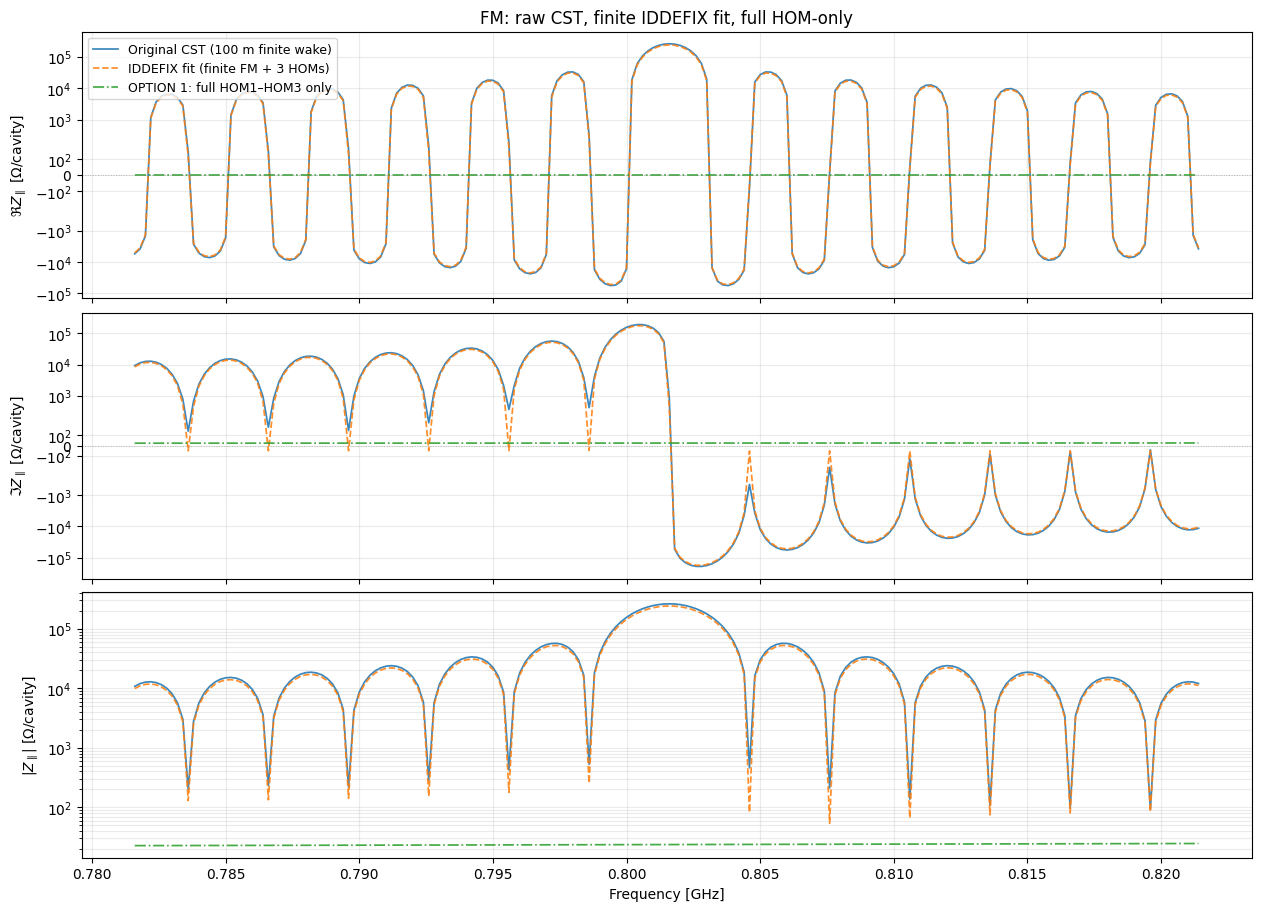

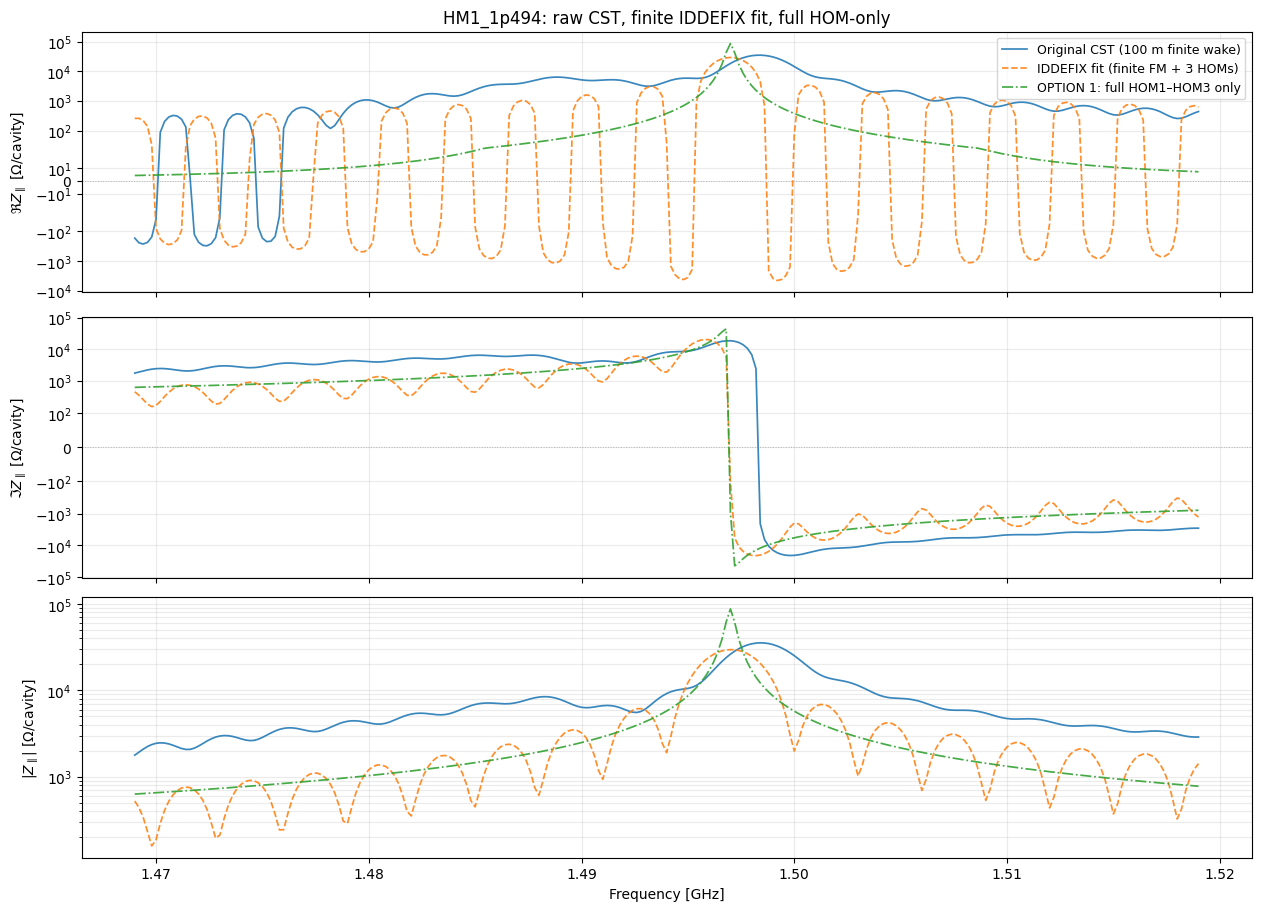

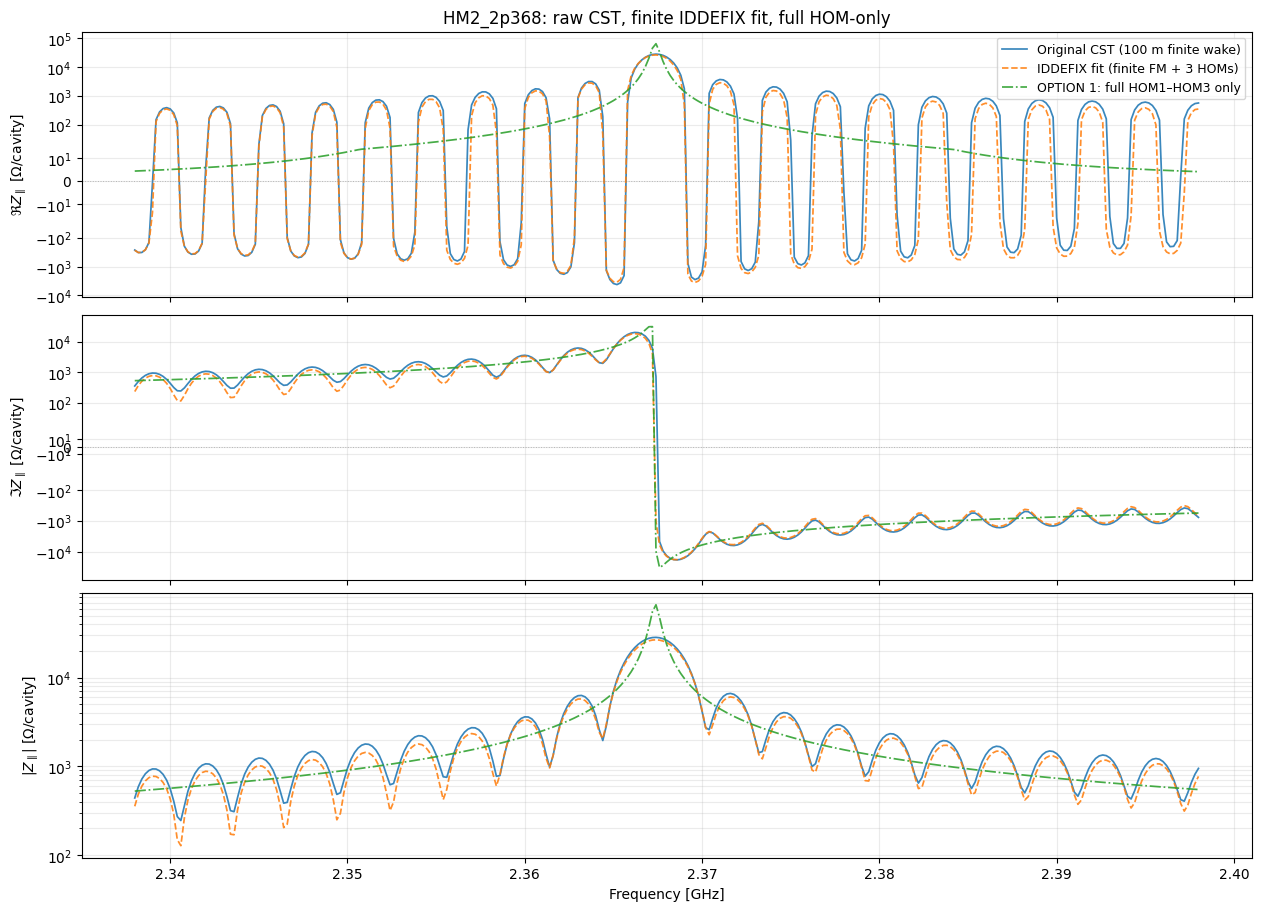

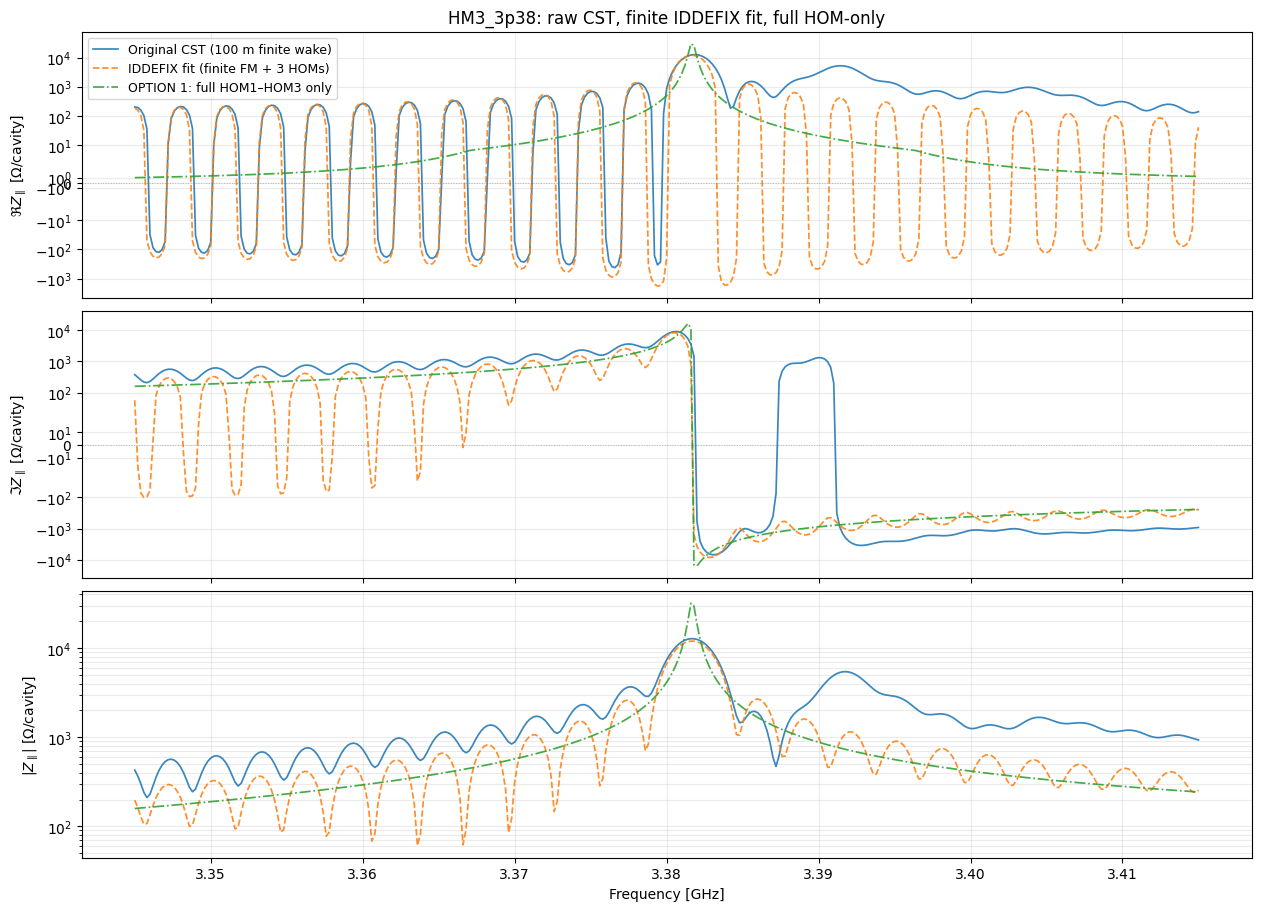

Saved figures:
   full /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/RF_Option1_0_to_3p55GHz.png
   FM /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/RF_Option1_zoom_FM.png
   HM1_1p494 /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/RF_Option1_zoom_HM1_1p494.png
   HM2_2p368 /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/RF_Option1_zoom_HM2_2p368.png
   HM3_3p38 /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/RF_Option1_zoom_HM3_3p38.png


In [8]:
for mode in MODES:
    select = np.abs(f_plot - mode['f_ref']) <= mode['half']
    subset = tuple(z[select] for z in curves)
    plots[mode['name']] = plot_impedance(
        f_plot[select], subset,
        f"{mode['name']}: raw CST, finite IDDEFIX fit, full HOM-only",
        f"RF_Option1_zoom_{mode['name']}.png")
print("Saved figures:")
for name, fp in plots.items(): print("  ", name, fp)

## 6 · Export the full HOM-only impedance to 50 GHz on an **adaptive grid**

**Critical:** the three HOMs have intrinsic full-widths \(f_r/Q\) of about 0.4–0.5 MHz. A uniform 10 MHz budget grid can miss the peaks and severely underestimate the RF loss factor. The output contains both a high-resolution adaptive file (recommended) and a 10 MHz compatibility/visualization file (**not reliable for narrow-HOM integrations**).

We also compute the 4 mm Gaussian-bunch loss factor:
\[
\kappa(\sigma_z)=2\int_{0}^{f_{\max}}\Re Z(f)
\exp[-(2\pi f\sigma_z/c)^2]\,df.
\]
For direct comparison, if the original filtered **3 mm CST** RF file exists, we evaluate the same integral from that separate input *as a reference only*. It is **not** used to fit or correct Option 1.

The adaptive grid also includes **logarithmically refined resonance wings extending 600 linewidths**; refining only the narrow central peaks is insufficient to certify the total loss factor.


**Numerical note:** the adaptive integration includes both central resonances and their long Lorentzian tails; the independent analytical wake-domain check in §8 verifies the resulting loss factor.


In [9]:
# First reproduce the V26.2 10 MHz sampling grid.
f_coarse = np.linspace(0., FMAX_EXPORT_HZ, int(FMAX_EXPORT_HZ/10e6) + 1)

# Add fine resonance cores and logarithmic wings extending hundreds of linewidths.
# A narrow-only patch (e.g. +/-10 MHz) can pass its local grid-refinement test
# but still bias the total HOM loss factor by ~0.1% due to coarsely sampled tails.
patches = []
for row in hom_fits:
    width = row['f_fit_hz'] / row['Q_fixed']
    f_center = row['f_fit_hz']
    inner_widths, outer_widths = 25, 600
    central = f_center + np.linspace(-inner_widths*width,
                                     inner_widths*width,
                                     2*inner_widths*30+1)
    wing_offset = np.geomspace(inner_widths*width, outer_widths*width, 500)
    patches.extend([central, f_center-wing_offset, f_center+wing_offset])
f_adaptive = np.unique(np.concatenate([f_coarse, *patches]))

def hom_only(f_hz):
    return sum((iddefix_full(f_hz, row['Rs_Ohm'], row['Q_fixed'], row['f_fit_hz'])
                for row in hom_fits), np.zeros_like(f_hz, dtype=complex))

z_adaptive = hom_only(f_adaptive)
z_coarse = hom_only(f_coarse)
assert np.all(z_adaptive.real >= -1e-9)

# Column order is f_GHz, ReZ_Ohm, ImZ_Ohm, AbsZ_Ohm.
def save_impedance(path, f, Z, n_cav):
    Z = Z*n_cav
    np.savetxt(path, np.column_stack([f/1e9, Z.real, Z.imag, np.abs(Z)]),
               header=f"f_GHz ReZ_Ohm ImZ_Ohm AbsZ_Ohm; {n_cav} cavity/cavities; "
                      "IDDEFIX full HOM1+HOM2+HOM3 only (FM excluded); "
                      "10mm CST/100m fitted; no broadband; provisional", fmt="%.12e")

per_cavity = RESULTS / "Z_RF_Option1_FULL_HOM_ONLY_per_cavity_ADAPTIVE_0to50GHz.txt"
ring_adaptive = RESULTS / "Z_RF_Option1_FULL_HOM_ONLY_112cav_ADAPTIVE_0to50GHz.txt"
coarse_file = RESULTS / "Z_RF_Option1_FULL_HOM_ONLY_per_cavity_10MHz_VISUAL_ONLY.txt"
save_impedance(per_cavity, f_adaptive, z_adaptive, 1)
save_impedance(ring_adaptive, f_adaptive, z_adaptive, N_RF_CAVITIES)
save_impedance(coarse_file, f_coarse, z_coarse, 1)

print(f"Adaptive grid: {len(f_adaptive):,} points; coarse grid: {len(f_coarse):,} points")
for row in hom_fits:
    print(f"{row['name']}: f_r = {row['f_fit_hz']/1e9:.6f} GHz, "
          f"FWHM ≈ {row['f_fit_hz']/row['Q_fixed']/1e6:.4f} MHz")
print("Saved:", per_cavity, ring_adaptive, coarse_file, sep="\n  ")

Adaptive grid: 12,498 points; coarse grid: 5,001 points
HM1_1p494: f_r = 1.496998 GHz, FWHM ≈ 0.3939 MHz
HM2_2p368: f_r = 2.367364 GHz, FWHM ≈ 0.4831 MHz
HM3_3p38: f_r = 3.381681 GHz, FWHM ≈ 0.4124 MHz
Saved:
  /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/Z_RF_Option1_FULL_HOM_ONLY_per_cavity_ADAPTIVE_0to50GHz.txt
  /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/Z_RF_Option1_FULL_HOM_ONLY_112cav_ADAPTIVE_0to50GHz.txt
  /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/Z_RF_Option1_FULL_HOM_ONLY_per_cavity_10MHz_VISUAL_ONLY.txt


In [10]:
def loss_factor_v_per_pc(f_hz, Z, sigma_z_m):
    weight = np.exp(-(2*np.pi*f_hz*sigma_z_m/c)**2)
    return float(2*trapezoid(np.real(Z)*weight, f_hz)*1e-12)

new_kappa = loss_factor_v_per_pc(f_adaptive, z_adaptive, SIGMA_BUDGET_M)
new_kappa_coarse = loss_factor_v_per_pc(f_coarse, z_coarse, SIGMA_BUDGET_M)
print(f"IDDEFIX HOM-only 4mm loss factor, 1 cavity (adaptive): {new_kappa:.6f} V/pC")
print(f"IDDEFIX HOM-only 4mm loss factor, {N_RF_CAVITIES} cavities (adaptive): {N_RF_CAVITIES*new_kappa:.6f} V/pC")
print(f"False 4mm loss factor if only 10 MHz grid is integrated: {new_kappa_coarse:.6f} V/pC / cavity")

old_3mm = DATA / 'Z_single_rf_cavity_long_filter_3mm.txt'
old_kappa = None
if old_3mm.is_file():
    old_table = np.loadtxt(old_3mm, comments='#')
    old_f = old_table[:,0]*1e9
    old_z = old_table[:,1]+1j*old_table[:,2]
    old_kappa = loss_factor_v_per_pc(old_f, old_z, SIGMA_BUDGET_M)
    print(f"Separate legacy filtered 3mm CST input, 4mm loss factor: {old_kappa:.6f} V/pC / cavity")
    print(f"Fraction retained by HOM-only vs old CST input: {new_kappa/old_kappa*100:.2f}%")
    if new_kappa < .5*old_kappa:
        print('WARNING: HOM-only omits major broadband/FM/unidentified contributions; NOT equivalent to original RF budget.')
else:
    print('Original 3 mm CST budget file not found; skipping old input comparison.')

# Off-resonance HOM tails are permitted near FM. There is no separate FM resonance.
f_fm = next(r for r in fits if r['name']=='FM')['f_fit_hz']
z_at_fm = hom_only(np.array([f_fm]))[0]
print(f"Option 1 at fitted FM frequency ({f_fm/1e6:.3f} MHz): "
      f"Re={z_at_fm.real:.6g}, Im={z_at_fm.imag:.6g} Ω / cavity (HOM tails only)")

IDDEFIX HOM-only 4mm loss factor, 1 cavity (adaptive): 0.245629 V/pC
IDDEFIX HOM-only 4mm loss factor, 112 cavities (adaptive): 27.510394 V/pC
False 4mm loss factor if only 10 MHz grid is integrated: 0.033935 V/pC / cavity
Separate legacy filtered 3mm CST input, 4mm loss factor: 2.522494 V/pC / cavity
Fraction retained by HOM-only vs old CST input: 9.74%
Option 1 at fitted FM frequency (801.602 MHz): Re=0.00387223, Im=23.6443 Ω / cavity (HOM tails only)


In [11]:
# Independent full-grid refinement test: double points across BOTH
# the resonance cores and the logarithmic wings, not only central peak bins.
extra_patches = []
for row in hom_fits:
    fr, width = row['f_fit_hz'], row['f_fit_hz']/row['Q_fixed']
    central = fr + np.linspace(-25*width, 25*width, 2*25*60+1)
    wing = np.geomspace(25*width, 600*width, 1000)
    extra_patches.extend([central, fr-wing, fr+wing])
f_refined = np.unique(np.concatenate([f_coarse, *extra_patches]))
k_refined = loss_factor_v_per_pc(f_refined, hom_only(f_refined), SIGMA_BUDGET_M)
refinement_error = abs(k_refined-new_kappa)/k_refined
print(f'Adaptive-grid refinement check (core + wings): {refinement_error:.2e} relative')
assert refinement_error < 2e-4
print("\nIndividual 4 mm HOM loss factors (112 cavities):")
for row in hom_fits:
    zi = iddefix_full(f_adaptive, row['Rs_Ohm'], row['Q_fixed'], row['f_fit_hz'])
    ki = loss_factor_v_per_pc(f_adaptive, zi, SIGMA_BUDGET_M)
    print(f"  {row['name']}: {ki*N_RF_CAVITIES:.4f} V/pC")

Adaptive-grid refinement check (core + wings): 1.78e-07 relative

Individual 4 mm HOM loss factors (112 cavities):
  HM1_1p494: 11.9992 V/pC
  HM2_2p368: 10.9374 V/pC
  HM3_3p38: 4.5738 V/pC


## 7 · Plot the exported passive three-HOM spectrum and sampling sensitivity

The full HOM-only \(\Re Z\) is nonnegative. The dotted points in the peak-resolution comparison show why the legacy 10 MHz grid is inadequate for integrating these narrow resonances.

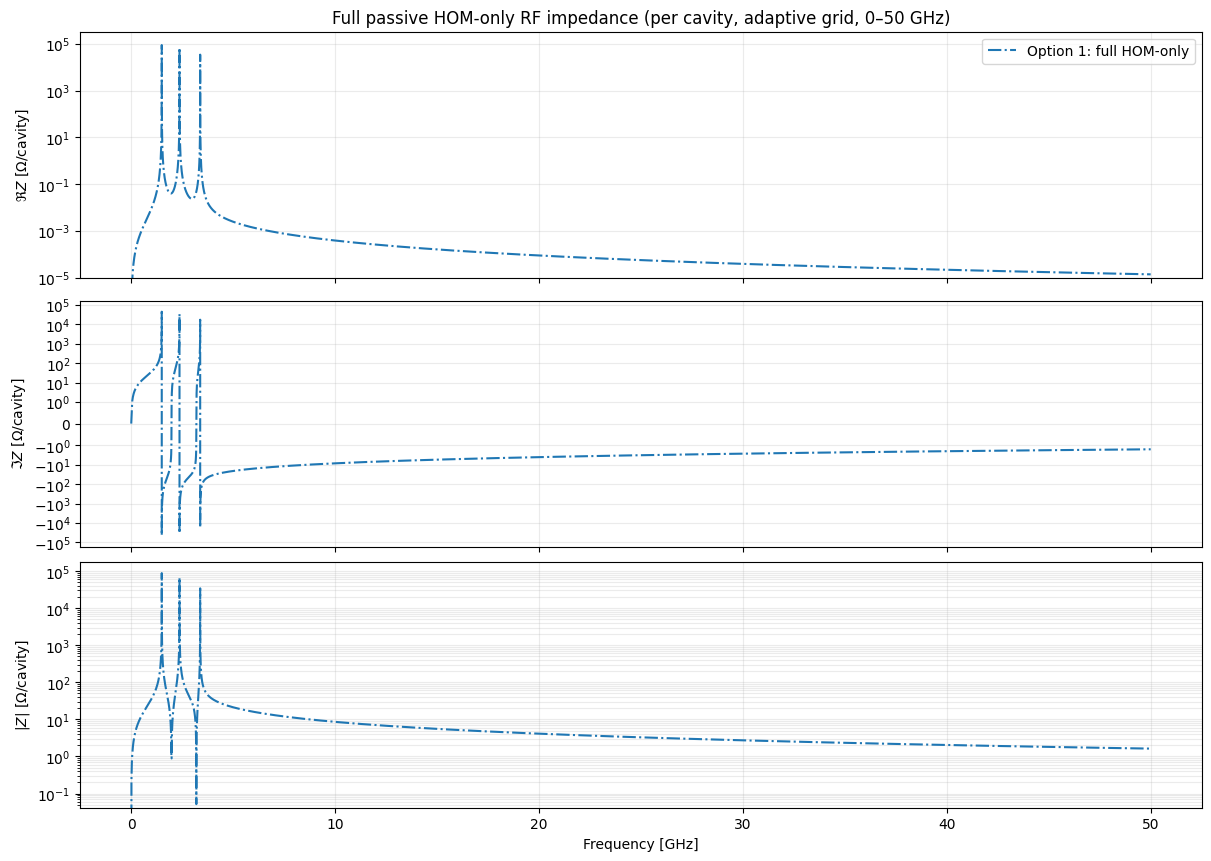

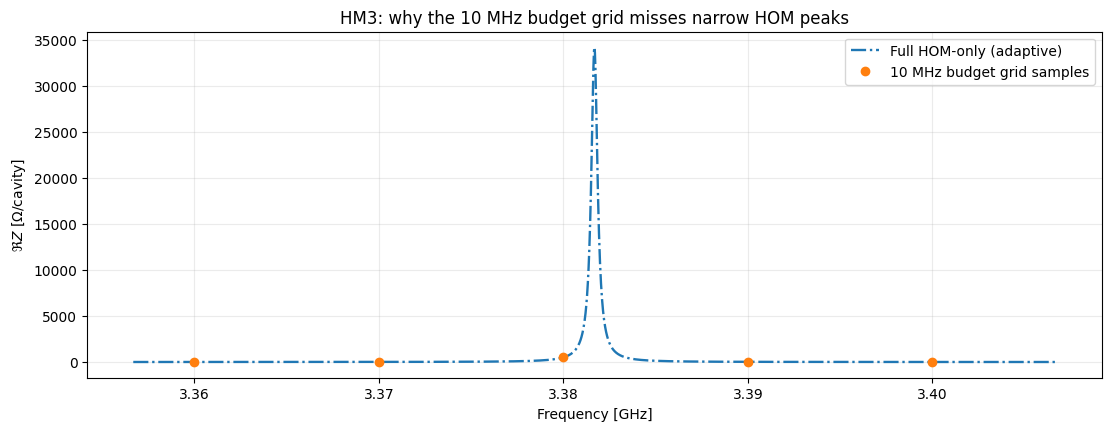

In [12]:
fig, axs = plt.subplots(3,1,figsize=(12,8.5),sharex=True,layout='constrained')
for ax, values, lab in zip(axs,
                           [z_adaptive.real, z_adaptive.imag, np.abs(z_adaptive)],
                           [r'$\Re Z$ [Ω/cavity]', r'$\Im Z$ [Ω/cavity]', r'$|Z|$ [Ω/cavity]']):
    ax.plot(f_adaptive/1e9, values, ls='-.', lw=1.5, label='Option 1: full HOM-only')
    if lab.startswith(r'$|'):
        ax.set_yscale('log')
        ax.set_ylim(bottom=max(np.min(np.abs(z_adaptive[np.abs(z_adaptive)>0]))*.8,1e-4))
    elif lab.startswith(r'$\Im'):
        ax.set_yscale('symlog',linthresh=1.)
    else:
        ax.set_yscale('log')
        ax.set_ylim(bottom=1e-5)
    ax.grid(True,which='both',alpha=.25)
    ax.set_ylabel(lab)
axs[0].legend()
axs[0].set_title('Full passive HOM-only RF impedance (per cavity, adaptive grid, 0–50 GHz)')
axs[-1].set_xlabel('Frequency [GHz]')
fig.savefig(RESULTS/'RF_Option1_0_to_50GHz.png',dpi=140)
display(fig)
plt.close(fig)

# Zoom into HM3: full model vs samples of the uniform 10 MHz grid.
row = next(r for r in hom_fits if r['name']=='HM3_3p38')
sel = np.abs(f_adaptive-row['f_fit_hz']) < 25e6
sel_coarse = np.abs(f_coarse-row['f_fit_hz']) < 25e6
fig, ax = plt.subplots(figsize=(11,4.2),layout='constrained')
ax.plot(f_adaptive[sel]/1e9, z_adaptive[sel].real, ls='-.', label='Full HOM-only (adaptive)', lw=1.7)
ax.plot(f_coarse[sel_coarse]/1e9, z_coarse[sel_coarse].real, marker='o', ls='none',
        label='10 MHz budget grid samples')
ax.set(xlabel='Frequency [GHz]', ylabel=r'$\Re Z$ [Ω/cavity]',
       title='HM3: why the 10 MHz budget grid misses narrow HOM peaks')
ax.grid(alpha=.25); ax.legend()
fig.savefig(RESULTS/'RF_Option1_HM3_adaptive_vs_10MHz.png',dpi=140)
display(fig)
plt.close(fig)

In [13]:
report = {
    "model": "IDDEFIX infinite-length HOM1 + HOM2 + HOM3 only; FM excluded",
    "fit": "v14/v15 fixed-Q local magnitude fit to 100m CST 10mm Gaussian bunch",
    "backend": IDDEFIX_BACKEND,
    "mode_parameters_per_cavity": fits,
    "n_cavities": N_RF_CAVITIES,
    "sigma_z_budget_m": SIGMA_BUDGET_M,
    "loss_factor_option1_V_per_pC_per_cavity_adaptive": new_kappa,
    "loss_factor_option1_V_per_pC_112_cavities_adaptive": N_RF_CAVITIES*new_kappa,
    "loss_factor_option1_V_per_pC_per_cavity_coarse10MHz_UNDERSAMPLED": new_kappa_coarse,
    "loss_factor_original_filtered_3mm_CST_per_cavity_if_available": old_kappa,
    "dct_dst_czt_relative_L2": float(dct_error),
    "cst_native_magnitude_median_relative_error": float(np.median(rel_native)),
    "warnings": [
        "Provisional fixed-Q fit. HM1 frequency reaches permitted fit boundary; HM3 has an unresolved secondary feature.",
        "No broadband residual, no 800 MHz fundamental, no omitted HOMs: it is not the full RF impedance.",
        "The 3mm filtered CST budget file is independent from the 100m 10mm fitted data.",
        "10MHz samples undersample narrow HOMs; use adaptive export or analytic resonator impedance for tracking.",
        "Do not automatically overwrite the HEB V26.2 official RF input.",
    ],
}
(RESULTS/'RF_Option1_fit_and_validation_report.json').write_text(json.dumps(report,indent=2))
print("Saved JSON report and all figures in:", RESULTS)

Saved JSON report and all figures in: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only



## 8 · Export **budget-compatible impedance and wakes** in `data/rf_cavities`

The file `Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt` has **exactly three columns**: `Frequency [GHz]`, `Re(Z) [Ω]`, `Im(Z) [Ω]`. It contains the impedance of **one cavity only**. The HEB PyWIT model already multiplies the RF contribution by 112, so **do not** import the ring-integrated table as its RF source.

We also export:

- **Point-charge wake**, in the sign convention of the original CST longitudinal wake files: `s [mm]`, `W [V/pC]`, for `0 ≤ s ≤ 200 mm`.
- **Gaussian-bunch wake potentials** for `σz = 0.4 mm` and `4 mm`, in the same `s [mm]`, `W [V/pC]` convention; both extend from `−10` to `200 mm`.
- The fitted HOM parameters and a provenance/validation manifest.

The underlying IDDEFIX point wake (for \(s>0\)) is

\[
 w_{\parallel}(s)=\sum_{j=1}^3 \frac{R_{s,j}\omega_j}{Q_j}
 e^{-B_j s/c}\left[\cos(C_j s/c)-\frac{B_j}{C_j}\sin(C_j s/c)\right],
\qquad B_j=\frac{\omega_j}{2Q_j},\ C_j=\sqrt{\omega_j^2-B_j^2}.
\]

We convolve this with the normalized Gaussian bunch *analytically*, using the standard complementary-error-function formula, rather than an under-resolved inverse FFT. In this HEB file convention the output wake is \(-w_\parallel/10^{12}\) in V/pC; the IDDEFIX wake itself uses the opposite longitudinal sign relative to the CST files. The point wake value at \(s=0\) is the **right-hand limit** \(W(0^+)\), not the half-sum.

**Caution about the model:** `HEBModel.bunch_wake_04mm()` internally evaluates impedance at a **40 MHz** frequency spacing by default, far too coarse to reproduce these ~0.4 MHz-wide HOMs. The direct analytical wake export below is the correct HOM-only reference for wake comparison; simply changing an input filename does *not* fix this undersampling in that existing function.


In [14]:

from scipy.special import erfc

# Conservative outputs: create *new* files, do not overwrite original CST or V26.2 RF data.
BUDGET_RF_DIR = DATA
BUDGET_RF_DIR.mkdir(parents=True, exist_ok=True)
Z_BUDGET_NAME = 'Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt'
POINT_WAKE_NAME = 'W_single_rf_cavity_long_IDDEFIX_HOM_only_POINT_0to200mm.txt'
WAKE_SIGMAS_MM = (0.4, 4.0)
WAKE_S_MIN_MM, WAKE_S_MAX_MM, WAKE_DS_MM = -10., 200., 0.025

# SOURCE_PATHS in heb_gold_tl.py expects 3 columns, frequencies in GHz, per-cavity Ohm.
z_budget_path = BUDGET_RF_DIR / Z_BUDGET_NAME
np.savetxt(
    z_budget_path,
    np.column_stack([f_adaptive / 1e9, z_adaptive.real, z_adaptive.imag]),
    fmt='%.12e',
    header=('Freq(GHz) Re(Z)[Ohm/cavity] Im(Z)[Ohm/cavity]; IDDEFIX full HOM1+HOM2+HOM3; '
            '800MHz FM excluded; NO broadband remainder; adaptive frequency grid; provisional')
)

# Analytic causal point-charge wake from *the same three fitted full resonators*.
def point_wake_iddefix_v_per_c(s_m):
    ss = np.atleast_1d(np.asarray(s_m, dtype=float))
    out = np.zeros_like(ss)
    positive = ss >= 0  # at s=0, use the causal right-hand limit W(0+)
    if not np.any(positive):
        return out
    tt = ss[positive] / c
    for row in hom_fits:
        Rs, Q, wr = row['Rs_Ohm'], row['Q_fixed'], 2*np.pi*row['f_fit_hz']
        B = wr / (2*Q)
        C = np.sqrt(wr*wr - B*B)
        out[positive] += (Rs*wr/Q) * np.exp(-B*tt) * (
            np.cos(C*tt) - (B/C)*np.sin(C*tt)
        )
    return out

# Exact Gaussian-convolved *wake potential*, using one-sided causal point wake.
# This formula is equivalent to iddefix.Wakes.Resonator_longitudinal_wake_potential
# in the underdamped Q>0.5 regime. sigma_z_m is a length, NOT a time.
def bunch_wake_iddefix_v_per_c(s_m, sigma_z_m):
    ss = np.atleast_1d(np.asarray(s_m, dtype=float))
    if sigma_z_m <= 0:
        raise ValueError('Gaussian sigma_z must be positive')
    t = ss/c
    sig_t = sigma_z_m/c
    out = np.zeros_like(t)
    for row in hom_fits:
        Rs, Q, wr = row['Rs_Ohm'], row['Q_fixed'], 2*np.pi*row['f_fit_hz']
        B = wr / (2*Q)
        C = np.sqrt(wr*wr - B*B)
        lam = -B + 1j*C
        # E[ exp(lam*u) H(u) ] under a Gaussian centered at t.
        arg = -(t + sig_t*sig_t*lam)/(np.sqrt(2)*sig_t)
        out += (Rs*wr/(2*Q)) * np.real(
            (1 + 1j*B/C) * np.exp(lam*t + 0.5*(lam*sig_t)**2) * erfc(arg)
        )
    return out

# Signs: IDDEFIX uses W>0 at 0+ for a passive longitudinal resonator;
# source CST wake files use the opposite longitudinal sign, so export -W/1e12.
# Use exactly representable grid containing s=0 and endpoints -10, +200 mm.
n_left = int(np.rint(abs(WAKE_S_MIN_MM)/WAKE_DS_MM))
n_right = int(np.rint(WAKE_S_MAX_MM/WAKE_DS_MM))
s_wake_mm = np.arange(-n_left, n_right + 1, dtype=float)*WAKE_DS_MM
assert np.isclose(s_wake_mm[0],WAKE_S_MIN_MM) and np.isclose(s_wake_mm[-1],WAKE_S_MAX_MM)
assert np.any(s_wake_mm == 0)

point_mask = s_wake_mm >= 0
s_point_mm = s_wake_mm[point_mask]
point_wake_cst_v_per_pc = -1e-12*point_wake_iddefix_v_per_c(s_point_mm*1e-3)
point_wake_path = BUDGET_RF_DIR / POINT_WAKE_NAME
np.savetxt(point_wake_path,
           np.column_stack([s_point_mm, point_wake_cst_v_per_pc]), fmt='%.12e',
           header=('s / mm    W_long [V/pC]; IDDEFIX HOM-only POINT wake; '
                   'CST longitudinal sign; W(0)=W(0+); per cavity; no 800MHz fundamental'))

wake_paths = {}
wake_potentials = {}
for sigma_mm in WAKE_SIGMAS_MM:
    name = f'W_single_rf_cavity_long_IDDEFIX_HOM_only_sigma{sigma_mm:g}mm.txt'
    arr = -1e-12*bunch_wake_iddefix_v_per_c(s_wake_mm*1e-3, sigma_mm*1e-3)
    p = BUDGET_RF_DIR / name
    np.savetxt(p, np.column_stack([s_wake_mm, arr]), fmt='%.12e',
               header=(f's / mm    W_long [V/pC]; Gaussian sigma_z={sigma_mm:g}mm; '
                       'IDDEFIX full HOM-only wake potential, CST longitudinal sign; '
                       'per cavity; FM excluded'))
    wake_paths[sigma_mm] = p
    wake_potentials[sigma_mm] = arr

# Same data as in the original fit, saved alongside exported wake/impedance sources.
fit_data_path = BUDGET_RF_DIR / 'RF_IDDEFIX_HOM_only_fitted_parameters.csv'
with fit_data_path.open('w', newline='') as stream:
    wr = csv.DictWriter(stream, fieldnames=list(fits[0].keys()))
    wr.writeheader()
    wr.writerows(fits)

print('Exported BUDGET-CANDIDATE files in:', BUDGET_RF_DIR)
for p in [z_budget_path, point_wake_path, *wake_paths.values(), fit_data_path]:
    print(' ', p.name, f'({p.stat().st_size/1024:.1f} KiB)')
print('Note: no existing CST or legacy RF budget files were modified.')


Exported BUDGET-CANDIDATE files in: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities
  Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt (704.2 KiB)
  W_single_rf_cavity_long_IDDEFIX_HOM_only_POINT_0to200mm.txt (300.9 KiB)
  W_single_rf_cavity_long_IDDEFIX_HOM_only_sigma0.4mm.txt (316.6 KiB)
  W_single_rf_cavity_long_IDDEFIX_HOM_only_sigma4mm.txt (316.6 KiB)
  RF_IDDEFIX_HOM_only_fitted_parameters.csv (0.5 KiB)
Note: no existing CST or legacy RF budget files were modified.



### 8.1 · Independent validation: full impedance versus analytic wake

For a normalized Gaussian bunch with rms length \(\sigma_z\), the longitudinal loss factor is
\[
\kappa(\sigma_z)= 2\int_0^\infty \operatorname{Re}Z(f)
\exp[-(2\pi f\sigma_z/c)^2]df
= w_{\mathrm{potential}}(s=0;\sqrt2\sigma_z).
\]

The second equality is an **independent** consistency check: it compares the frequency-domain full HOM model with its analytical Gaussian-convolved point wake. The negative sign is applied only when exporting the result in the CST wake convention.


In [15]:

# The 4 mm loss factor from the two independent domains must agree.
kappa_from_bunch_potential = float(
    bunch_wake_iddefix_v_per_c(np.array([0.]), np.sqrt(2)*SIGMA_BUDGET_M)[0] * 1e-12
)
kappa_from_frequency = new_kappa
kappa_relative_difference = abs(kappa_from_bunch_potential - kappa_from_frequency) / max(kappa_from_frequency, 1e-100)
print(f'κ(4 mm), frequency-domain adaptive Z: {kappa_from_frequency:.8f} V/pC per cavity')
print(f'κ(4 mm), wake-domain Gaussian convolution: {kappa_from_bunch_potential:.8f} V/pC per cavity')
print(f'Independent relative difference: {kappa_relative_difference:.3e}')
assert kappa_relative_difference < 5e-5

# Confirm source files have the expected units, columns, monotonicity, and values.
z_verify = np.loadtxt(z_budget_path)
assert z_verify.shape[1] == 3 and len(z_verify) == len(f_adaptive)
assert np.all(np.diff(z_verify[:,0]) > 0) and np.min(z_verify[:,1]) >= -1e-7
np.testing.assert_allclose(z_verify[:,1], z_adaptive.real, rtol=1e-9, atol=1e-9)
for sigma_mm, p in wake_paths.items():
    check = np.loadtxt(p)
    assert check.shape[1] == 2 and len(check) == len(s_wake_mm)
    assert np.all(np.diff(check[:,0]) > 0) and np.isfinite(check).all()
    assert np.allclose(check[:,1], wake_potentials[sigma_mm], rtol=1e-9, atol=1e-12)
print('PASS: 3-column adaptive impedance and 2-column wake files validated.')

manifest = {
    'model': 'Option 1: full HOM1+HOM2+HOM3 (no FM, no CST broadband)',
    'source_fit': 'v14/v15 fixed-Q local magnitude fit; 100m CST wake, 10mm bunch',
    'fit_parameters': fits,
    'n_cavities_in_ring': N_RF_CAVITIES,
    'source_file_normalization': 'SINGLE CAVITY: multiply by 112 only in the HEB model',
    'frequency_grid': 'adaptive with dense windows around all HOMs, 0..50 GHz',
    'wake_data': 'V/pC per cavity, CST longitudinal sign = -(IDDEFIX V/C)/1e12',
    'data_files': {
        'impedance_per_cavity': z_budget_path.name,
        'point_wake_per_cavity': point_wake_path.name,
        'gaussian_wake_potential_per_cavity': {f'{k:g}mm':p.name for k,p in wake_paths.items()},
        'fitted_parameters': fit_data_path.name,
    },
    'validation': {
        'kappa_4mm_Z_V_per_pC_per_cavity': kappa_from_frequency,
        'kappa_4mm_wake_V_per_pC_per_cavity': kappa_from_bunch_potential,
        'kappa_relative_difference': kappa_relative_difference,
    },
    'warnings': [
        'DO NOT feed the 112-cavity impedance into a model that multiplies by 112.',
        'DO NOT overwrite the original RF/CST source without independent validation.',
        'The HEB default 10MHz budget sampling, and especially 40MHz bunch-wake sampling, MISS high-Q HOM peaks.',
        'For wake-budget studies, use direct analytical bunch-wake file, or evaluate resonator Z adaptively in inverse transform.',
        'FM is omitted intentionally; no broadband contribution or unresolved modes are modeled.',
        'This is LONGITUDINAL only; RF dipolar impedances and wakes remain unchanged.',
    ],
}
manifest_path = BUDGET_RF_DIR / 'RF_IDDEFIX_HOM_only_budget_manifest.json'
manifest_path.write_text(json.dumps(manifest, indent=2))
print('Wrote:', manifest_path.name)


κ(4 mm), frequency-domain adaptive Z: 0.24562851 V/pC per cavity
κ(4 mm), wake-domain Gaussian convolution: 0.24562843 V/pC per cavity
Independent relative difference: 3.643e-07
PASS: 3-column adaptive impedance and 2-column wake files validated.
Wrote: RF_IDDEFIX_HOM_only_budget_manifest.json


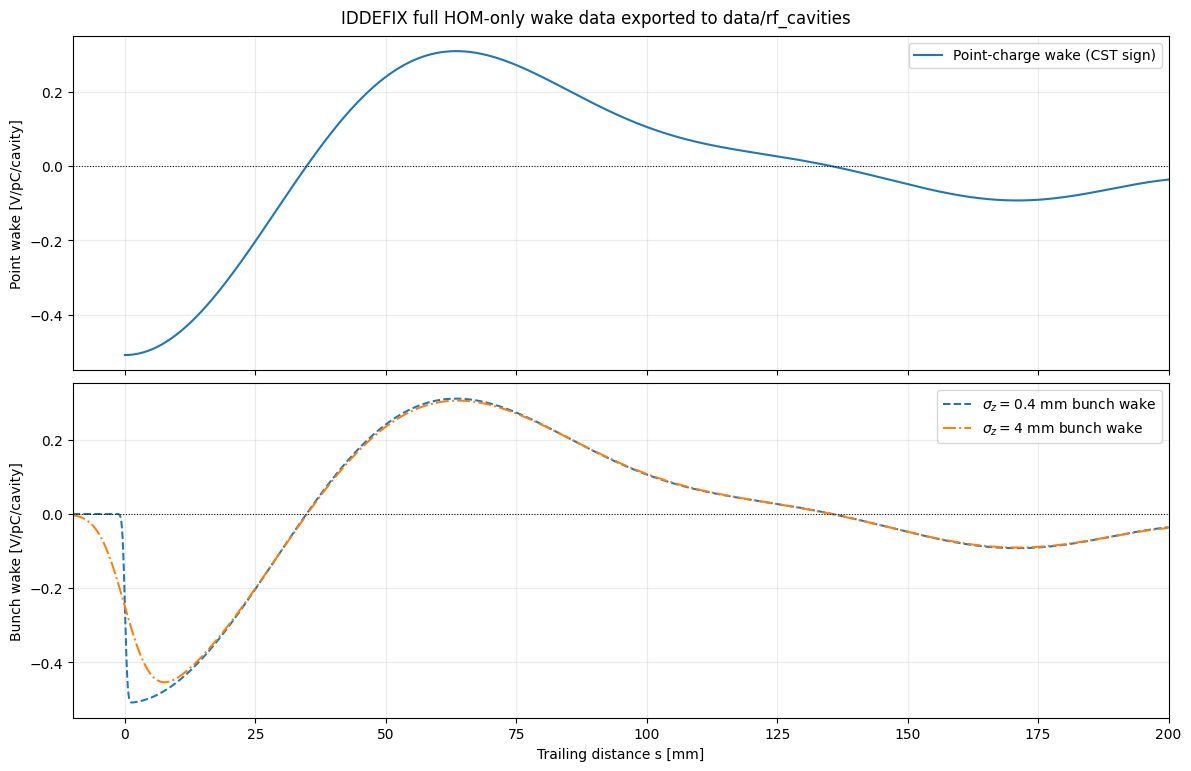

Saved: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/results/RF_IDDEFIX_option1_HOM_only/RF_Option1_BUDGET_exported_point_and_bunch_wakes.png


In [16]:

# All curves below are generated *directly* from the fitted HOM parameters.
fig, axes = plt.subplots(2, 1, figsize=(11.8, 7.6), sharex=True, layout='constrained')
axes[0].plot(s_point_mm, point_wake_cst_v_per_pc, color='tab:blue', lw=1.5,
             label='Point-charge wake (CST sign)')
axes[0].axhline(0, color='black', ls=':', lw=.75)
axes[0].set_ylabel('Point wake [V/pC/cavity]')
axes[0].legend()
for sigma_mm, vals in wake_potentials.items():
    axes[1].plot(s_wake_mm, vals, lw=1.45, ls='--' if sigma_mm == .4 else '-.',
                 label=fr'$\sigma_z={sigma_mm:g}$ mm bunch wake')
axes[1].axhline(0, color='black', ls=':', lw=.75)
axes[1].set_xlabel('Trailing distance s [mm]')
axes[1].set_ylabel('Bunch wake [V/pC/cavity]')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=.25)
    ax.set_xlim(-10, 200)
fig.suptitle('IDDEFIX full HOM-only wake data exported to data/rf_cavities')
fig_path = RESULTS / 'RF_Option1_BUDGET_exported_point_and_bunch_wakes.png'
fig.savefig(fig_path, dpi=135)
plt.show()
print('Saved:', fig_path)



### 8.2 · How to connect the candidate model to V26.2

The existing HEB model reads its RF impedance source from the `SOURCE_PATHS` dictionary in `heb_gold_tl.py`. After deciding to use Option 1, change the **longitudinal RF path only** to

```python
'RF': {
    'long': 'rf_cavities/Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt',
    'x': 'rf_cavities/Z_single_rf_cavity_dipx_filter_3mm.txt',
    'y': 'rf_cavities/Z_single_rf_cavity_dipy_filter_3mm.txt',
}
```

**No changes are made automatically to the official model.** `HEBModel.component_impedance('RF','long',f)` multiplies a one-cavity source by 112. For a narrow-HOM-aware loss factor, use the adaptive frequency samples rather than the default 0–50 GHz 10 MHz budget grid. If reconstructing the HOM-only bunch wake, **do not** use `HEBModel.bunch_wake_04mm()` with its default 40 MHz frequency grid: use the analytic `W_..._sigma0.4mm.txt` file exported here, or revise that inverse transform to resolve the HOMs.

This is a **provisional HOM-only alternative** to the present full CST RF model. It intentionally omits the 800 MHz accelerating mode and the unmodeled broadband contribution, which substantially changes the RF loss factor. The files are saved under distinct names, leaving legacy sources intact.


## Interpretation and limitations

**Option 1 is intentionally minimalist.** The frequency-dependent *HOM tails* remain at 800 MHz, but the high-\(Q\) **fundamental resonator is not included**. We do **not** subtract any contributions from CST, so there is no double-counting: the final exported impedance is **created from the three full resonators**, not added to the original CST data.

A smooth positive \(\Re Z\) is necessary for this passive resonator candidate, but does not establish completeness. The HM1 frequency reaches the allowed local search boundary and HM3 retains an unexplained right-hand structure; their uncertainties are not captured by fixing \(Q\). More importantly, dropping broadband impedance and FM changes the RF loss factor considerably. Direct application to V26.2 would require a documented model-scope decision and a fine-frequency treatment of narrow modes.